In [125]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [126]:
df = pd.read_csv('uber.csv')

In [127]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [128]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 23.4 MB


In [129]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [130]:
df = df.dropna()
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

In [131]:
df = df.drop('key',axis=1)

In [132]:
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'])

In [133]:
df['hour'] = df['pickup_datetime'].dt.hour
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year
df['dow'] = df['pickup_datetime'].dt.day_of_week
df = df.drop('pickup_datetime',axis=1)
df.head()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,month,year,dow
0,24238194,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,5,2015,3
1,27835199,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,7,2009,4
2,44984355,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,8,2009,0
3,25894730,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,6,2009,4
4,17610152,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,8,2014,3


In [134]:
df['distance'] = (
    ((df['pickup_longitude'] - df['dropoff_longitude'])**2 + (df['pickup_latitude'] - df['dropoff_latitude']) ** 2) **0.5 
)

In [135]:
df = df.drop(['pickup_longitude','dropoff_longitude','pickup_latitude','dropoff_latitude'], axis=1)

In [136]:
df.head()

,Unnamed: 0,fare_amount,passenger_count,hour,month,year,dow,distance
0,24238194,7.5,1,19,5,2015,3,0.015140
1,27835199,7.7,1,20,7,2009,4,0.022103
2,44984355,12.9,1,21,8,2009,0,0.053109
3,25894730,5.3,3,8,6,2009,4,0.016528
4,17610152,16.0,5,17,8,2014,3,0.051031


<Axes: xlabel='fare_amount'>

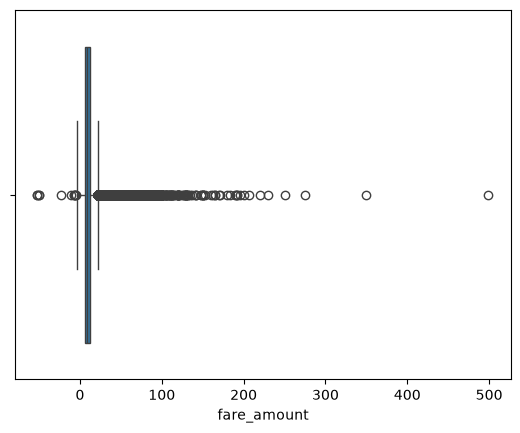

In [137]:
sns.boxplot(x=df['fare_amount'])

<Axes: xlabel='distance'>

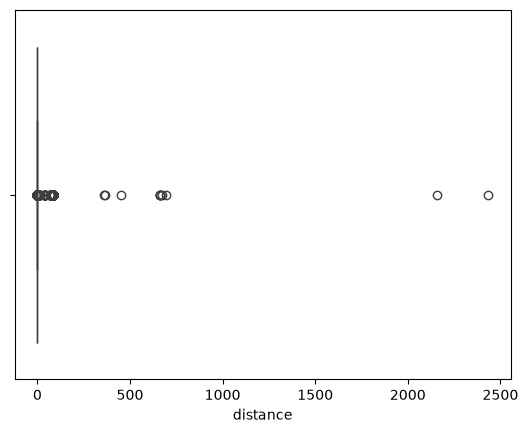

In [138]:
sns.boxplot(x=df['distance'])

In [139]:
def remove_outliers(df,column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5*IQR
    upper_limit = Q3 + 1.5*IQR

    df = df[
        (df[column] >= lower_limit) &
        (df[column] <= upper_limit)
    ]
    return df
    

In [140]:
df = remove_outliers(df,'fare_amount')
df = remove_outliers(df,'distance')


In [141]:
df = df[df['fare_amount'] > 0]

<Axes: >

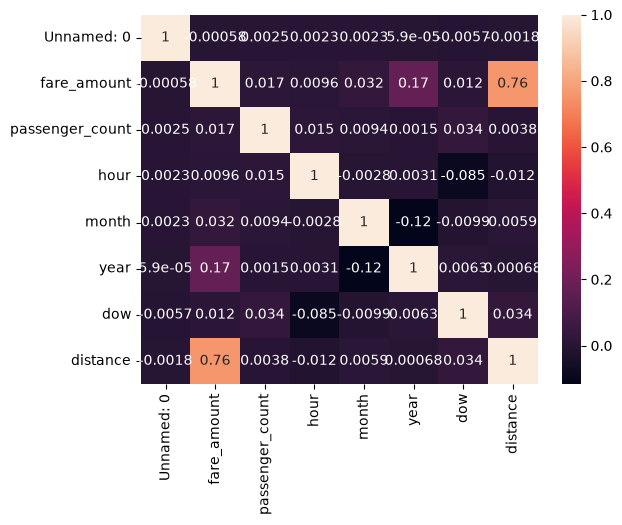

In [142]:
sns.heatmap(df.corr(),annot=True)

In [143]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score

In [144]:
pd.to_numeric(df['fare_amount'], errors='coerce')

0          7.5
1          7.7
2         12.9
3          5.3
4         16.0
          ... 
199994    12.0
199995     3.0
199996     7.5
199998    14.5
199999    14.1
Name: fare_amount, Length: 174468, dtype: float64

In [145]:

X = df.drop('fare_amount',axis=1)
y = df['fare_amount']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [146]:
X_train.head()

,Unnamed: 0,passenger_count,hour,month,year,dow,distance
54984,28082500,1,8,10,2009,3,0.026011
171278,4109206,1,10,7,2009,0,0.015744
36732,51025959,5,22,3,2009,5,0.011940
20615,26614896,1,22,10,2011,6,0.014211
51469,12369787,1,0,12,2012,3,0.000000


In [147]:
lr = LinearRegression()
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 0., 0., 0.,..., 0.,-0.,-0.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['Unnamed: 0','passenger_count','hour',...,'year','dow','distance']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8.554
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [148]:
y_pred_lr = lr.predict(X_test)
y_pred_lr

array([8.5546537 , 8.55428451, 8.5553181 , ..., 8.55469198, 8.55535893,
       8.55451351], shape=(34894,))

In [149]:
y_test

154487     3.3
85163      9.5
48864      7.3
134091     6.5
57448      6.9
          ... 
165215     8.0
185085     5.3
30709     18.1
126712     9.5
171889     4.5
Name: fare_amount, Length: 34894, dtype: float64

In [150]:
print("MSE:", mean_squared_error(y_test, y_pred_lr))
print("R2 Score:", r2_score(y_test, y_pred_lr))

MSE: 13.876364955808839
R2 Score: -6.921481691102294e-05
